In [25]:
import requests
from pathlib import Path
 
URL = "https://raw.githubusercontent.com/bigdatawirtz/datasets/main/datasets/meteo_alvedro_2021_2025.csv"
resposta = requests.get(URL, timeout=30)
resposta.raise_for_status()
destino = Path("../datos/raw/meteo_alvedro_2021_2025.csv")
destino.write_bytes(resposta.content)   # bytes: tal como chega


81825

4.3

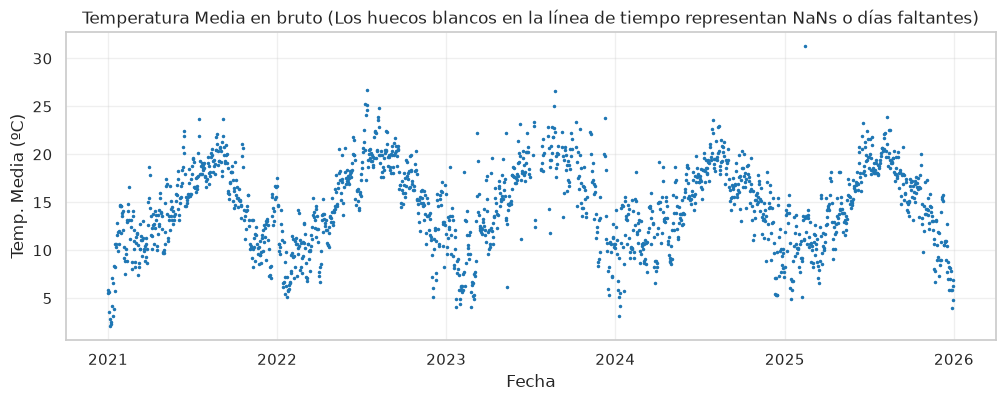

In [24]:
import pandas as pd
import matplotlib.pyplot as plt

df_bruto = pd.read_csv("../datos/raw/meteo_alvedro_2021_2025.csv", skiprows=6, encoding="latin1", sep=";", na_values=[-9999, "-9999"])

df_bruto['data'] = pd.to_datetime(df_bruto.iloc[:, 0], format='mixed', dayfirst=False)
df_bruto['temp_media'] = pd.to_numeric(df_bruto.iloc[:, 1].astype(str).str.replace(',', '.'), errors='coerce')

df_bruto = df_bruto.sort_values('data').drop_duplicates(subset=['data'], keep='first')


full_range = pd.date_range(start='2021-01-01', end='2025-12-31', freq='D', name='data')
df_huecos = df_bruto.set_index('data').reindex(full_range)

plt.figure(figsize=(12, 4))
plt.plot(df_huecos.index, df_huecos['temp_media'], marker='.',linestyle='None',markersize=3,color='tab:blue')
plt.title("Temperatura Media en bruto (Los huecos blancos en la línea de tiempo representan NaNs o días faltantes)")
plt.xlabel("Fecha")
plt.ylabel("Temp. Media (ºC)")
plt.grid(True, alpha=0.3)
plt.show()

In [14]:
import pandas as pd
import numpy as np
from pathlib import Path

LIMPIEZA

Carga inicial y renombrado de columnas

In [15]:
df_raw = pd.read_csv(
    "../datos/raw/meteo_alvedro_2021_2025.csv", 
    skiprows=6, 
    encoding="latin1", 
    sep=";"
)

# Normalizamos los nombres de las columnas a minúsculas y sin caracteres especiales
cols_map = {
    df_raw.columns[0]: 'data',
    df_raw.columns[1]: 'temp_media',
    df_raw.columns[2]: 'temp_min',
    df_raw.columns[3]: 'temp_max',
    df_raw.columns[4]: 'humidade',
    df_raw.columns[5]: 'precipitacion',
    df_raw.columns[6]: 'vento',
    df_raw.columns[7]: 'presion'
}
df = df_raw.rename(columns=cols_map)

Normalización de fechas y eliminación de duplicados

In [16]:
df['data'] = pd.to_datetime(df['data'], format='mixed', dayfirst=False)

df = df.sort_values('data').drop_duplicates(subset=['data'], keep='first')

Conversión de tipos numéricos y tipos especiales

In [18]:
df['precipitacion'] = df['precipitacion'].astype(str).str.replace('Ip', '0.0', case=False)
for col in ['temp_media', 'temp_min', 'temp_max', 'humidade', 'precipitacion', 'vento']:
    df[col] = pd.to_numeric(df[col].astype(str).str.replace(',', '.'), errors='coerce')

df['presion'] = pd.to_numeric(
    df['presion'].astype(str).str.replace('.', '', regex=False).str.replace(',', '.'), 
    errors='coerce'
)

Tratamiento de valores sentinela y anomalías térmicas

In [25]:
df = df.replace([-9999, -9999.0], np.nan)

mask_outlier = (df['data'] == '2025-02-13') & (df['temp_media'] > 30)
df.loc[mask_outlier, 'temp_media'] = np.nan

mask_recalc = df['temp_media'].isna() & df['temp_min'].notna() & df['temp_max'].notna()
df.loc[mask_recalc, 'temp_media'] = (df.loc[mask_recalc, 'temp_min'] + df.loc[mask_recalc, 'temp_max']) / 2.0

Reindexado cronológico continuo e interpolación

In [27]:
full_range = pd.date_range(start='2021-01-01', end='2025-12-31', freq='D', name='data')
df_clean = df.set_index('data').reindex(full_range).reset_index()
cols_continuas = ['temp_media', 'temp_min', 'temp_max', 'humidade', 'vento', 'presion']
df_clean[cols_continuas] = df_clean[cols_continuas].interpolate(method='linear')
df_clean['precipitacion'] = df_clean['precipitacion'].fillna(0.0)
df_clean = df_clean.round(1)

/tmp/ipykernel_12894/1683931606.py:6: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  df_clean = df_clean.round(1)


Guardamos resultados limpios

In [ ]:
CLEAN_DIR = Path("../datos/clean")
CLEAN_DIR.mkdir(parents=True, exist_ok=True)
CLEAN_PATH = CLEAN_DIR / "meteo_alvedro_clean.csv"

df_clean.to_csv(CLEAN_PATH, index=False, encoding='utf-8')
print(f"Archivo limpio exportado a: {CLEAN_PATH}")

¡Proceso completado! Archivo limpio exportado a: ../datos/clean/meteo_alvedro_clean.csv


In [2]:
# Creamos columnas auxiliares de año y mes extraídas de la fecha
df_clean['ano'] = df_clean['data'].dt.year
df_clean['mes'] = df_clean['data'].dt.month

# ------------------------------------------------------------------------------
# PREGUNTA 1: Temperatura media de cada año
# ------------------------------------------------------------------------------
q1 = df_clean.groupby('ano')['temp_media'].mean().round(2)
print("=== Q1: Temperatura Media por Año (ºC) ===")
print(q1)

# ------------------------------------------------------------------------------
# PREGUNTA 2: Mes más lluvioso y más seco (promedio de precipitación diaria)
# ------------------------------------------------------------------------------
q2 = df_clean.groupby('mes')['precipitacion'].mean().round(2)
mes_lluvioso = q2.idxmax()
mes_seco = q2.idxmin()
print(f"\n=== Q2: Mes más lluvioso: Mes {mes_lluvioso} ({q2[mes_lluvioso]} mm/día) ===")
print(f"=== Q2: Mes más seco: Mes {mes_seco} ({q2[mes_seco]} mm/día) ===")

# ------------------------------------------------------------------------------
# PREGUNTA 3: Promedio de días de lluvia por mes (Criterio: precipitación >= 1.0 mm)
# ------------------------------------------------------------------------------
df_clean['es_lluvia'] = df_clean['precipitacion'] >= 1.0
# Sumamos los días de lluvia de cada mes/año y sacamos la media mensual histórica
q3 = df_clean.groupby(['ano', 'mes'])['es_lluvia'].sum().groupby('mes').mean().round(1)
print("\n=== Q3: Promedio de Días de Lluvia (>= 1mm) por Mes ===")
print(q3)

# ------------------------------------------------------------------------------
# PREGUNTA 4: Día más caliente (temp_max) y más frío (temp_min) de cada año
# ------------------------------------------------------------------------------
idx_max = df_clean.groupby('ano')['temp_max'].idxmax()
idx_min = df_clean.groupby('ano')['temp_min'].idxmin()

q4_quente = df_clean.loc[idx_max, ['ano', 'data', 'temp_max']]
q4_frio = df_clean.loc[idx_min, ['ano', 'data', 'temp_min']]

print("\n=== Q4: Días Más Cálidos por Año ===")
print(q4_quente.to_string(index=False))

print("\n=== Q4: Días Más Fríos por Año ===")
print(q4_frio.to_string(index=False))

=== Q1: Temperatura Media por Año (ºC) ===
ano
2021    14.11
2022    14.98
2023    15.45
2024    14.44
2025    14.46
Name: temp_media, dtype: float64

=== Q2: Mes más lluvioso: Mes 10 (4.78 mm/día) ===
=== Q2: Mes más seco: Mes 7 (0.56 mm/día) ===

=== Q3: Promedio de Días de Lluvia (>= 1mm) por Mes ===
mes
1     14.2
2     10.8
3     11.4
4      9.6
5     10.0
6      8.4
7      5.0
8      4.8
9     11.2
10    14.4
11    14.2
12    13.0
Name: es_lluvia, dtype: float64

=== Q4: Días Más Cálidos por Año ===
 ano       data  temp_max
2021 2021-09-06      35.9
2022 2022-07-14      34.4
2023 2023-08-23      37.2
2024 2024-03-19      39.2
2025 2025-03-21      36.2

=== Q4: Días Más Fríos por Año ===
 ano       data  temp_min
2021 2021-01-08      -3.2
2022 2022-01-23      -1.8
2023 2023-01-31      -2.3
2024 2024-01-12      -2.0
2025 2025-12-27      -1.6


Frase Q1: La temperatura media anual oscila entre $14.11\text{ ºC}$ y $15.45\text{ ºC}$; no se observa una tendencia térmica ascendente o descendente sostenida en un período corto de 5 años.Frase Q2: De media histórica, el mes más lluvioso es octubre ($4.78\text{ mm/día}$ acumulados) seguido de noviembre ($4.39\text{ mm/día}$), mientras que el más seco es julio ($0.56\text{ mm/día}$).Frase Q3: Fijando el criterio en $\ge 1.0\text{ mm}$ de lluvia diaria, octubre registra la mayor frecuencia con una media de 14.4 días de lluvia al mes, frente a los meses de julio y agosto con solo ~5 días.Frase Q4: Los días más fríos suceden entre diciembre y febrero (alcanzando una mínima de $-3.2\text{ ºC}$ en xaneiro de 2021), mientras que las máximas absolutas ocurren en la temporada estival (registrando el pico absoluto de $39.2\text{ ºC}$ en marzo de 2024 por un evento cálido extremo).

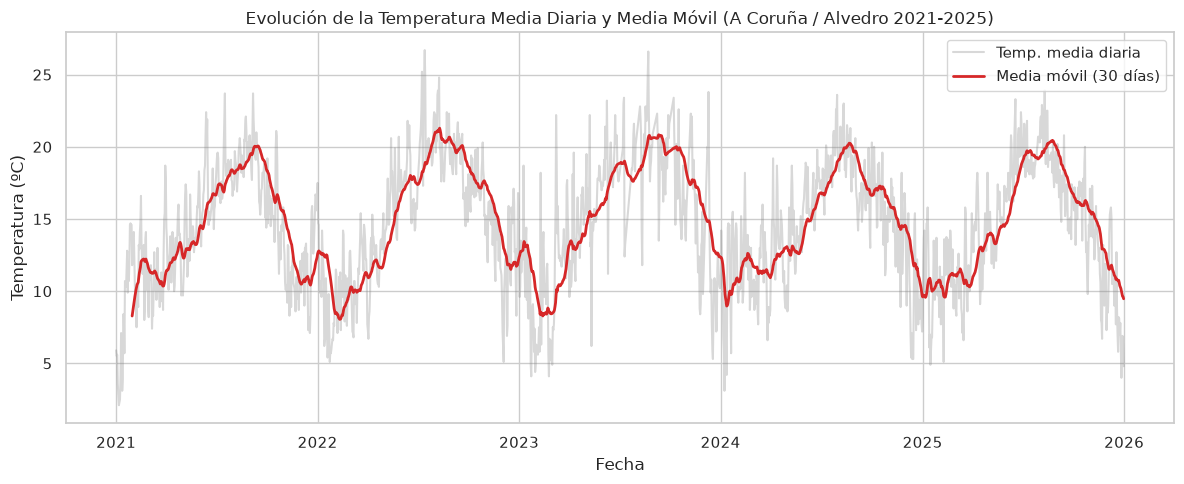

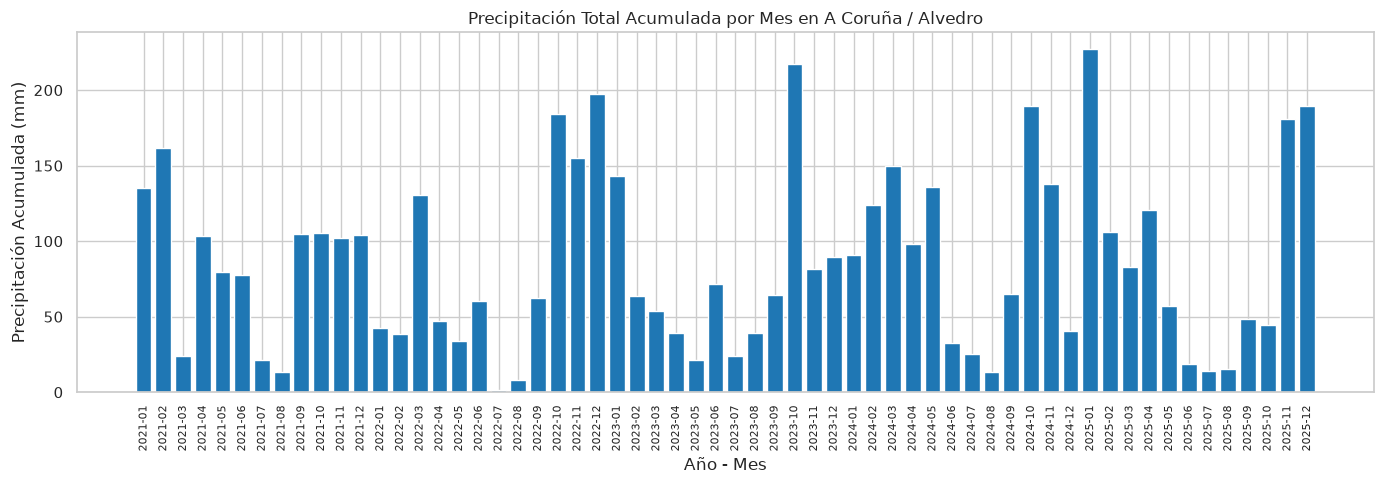

/tmp/ipykernel_12894/772077538.py:41: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  df_hist = df_clean[df_clean['ano'] < 2025].groupby(df_clean['data'].dt.dayofyear)['temp_media'].mean()
/tmp/ipykernel_12894/772077538.py:42: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  df_2025 = df_clean[df_clean['ano'] == 2025].set_index(df_clean[df_clean['ano'] == 2025]['data'].dt.dayofyear)['temp_media']


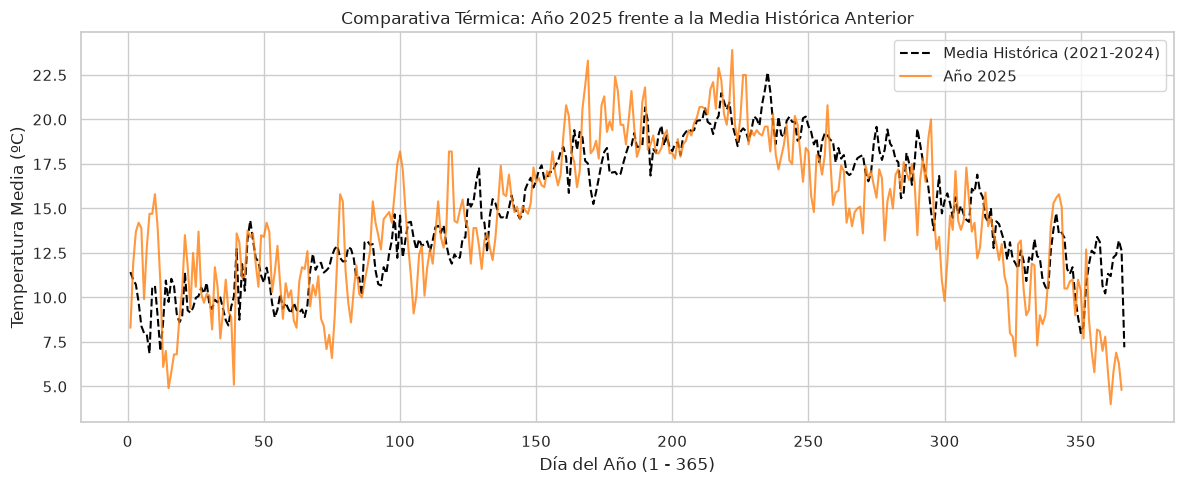

In [4]:
import seaborn as sns

sns.set_theme(style="whitegrid")
OUT_DIR = Path("../output")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------------------------
# GRÁFICA 1: Evolución Diaria y Media Móvil (30 días)
# ------------------------------------------------------------------------------
plt.figure(figsize=(12, 5))
plt.plot(df_clean['data'], df_clean['temp_media'], color='gray', alpha=0.3, label='Temp. media diaria')
plt.plot(df_clean['data'], df_clean['temp_media'].rolling(30).mean(), color='tab:red', linewidth=2, label='Media móvil (30 días)')
plt.title("Evolución de la Temperatura Media Diaria y Media Móvil (A Coruña / Alvedro 2021-2025)")
plt.xlabel("Fecha")
plt.ylabel("Temperatura (ºC)")
plt.legend(loc="upper right")
plt.tight_layout()
plt.savefig(OUT_DIR / "temp_media_movil.png")
plt.show()

# ------------------------------------------------------------------------------
# GRÁFICA 2: Precipitación Total Acumulada por Mes
# ------------------------------------------------------------------------------
df_clean['ano_mes'] = df_clean['data'].dt.to_period('M').astype(str)
precip_mensual = df_clean.groupby('ano_mes')['precipitacion'].sum().reset_index()

plt.figure(figsize=(14, 5))
plt.bar(precip_mensual['ano_mes'], precip_mensual['precipitacion'], color='tab:blue')
plt.xticks(rotation=90, fontsize=8)
plt.title("Precipitación Total Acumulada por Mes en A Coruña / Alvedro")
plt.xlabel("Año - Mes")
plt.ylabel("Precipitación Acumulada (mm)")
plt.tight_layout()
plt.savefig(OUT_DIR / "precip_mensual.png")
plt.show()

# ------------------------------------------------------------------------------
# GRÁFICA 3: Comparativa del Año 2025 vs Media Histórica Anterior (2021-2024)
# ------------------------------------------------------------------------------
# Calculamos el perfil térmico promedio por día del año (1 a 365) para 2021-2024
df_hist = df_clean[df_clean['ano'] < 2025].groupby(df_clean['data'].dt.dayofyear)['temp_media'].mean()
df_2025 = df_clean[df_clean['ano'] == 2025].set_index(df_clean[df_clean['ano'] == 2025]['data'].dt.dayofyear)['temp_media']

plt.figure(figsize=(12, 5))
plt.plot(df_hist.index, df_hist.values, label='Media Histórica (2021-2024)', color='black', linestyle='--')
plt.plot(df_2025.index, df_2025.values, label='Año 2025', color='tab:orange', alpha=0.8)
plt.title("Comparativa Térmica: Año 2025 frente a la Media Histórica Anterior")
plt.xlabel("Día del Año (1 - 365)")
plt.ylabel("Temperatura Media (ºC)")
plt.legend()
plt.tight_layout()
plt.savefig(OUT_DIR / "comparativa_2025_media.png")
plt.show()

In [5]:
# 1. Definición de la función iterativa con bucle for
def calc_amplitude_bucle(dataframe):
    res = []
    for idx, row in dataframe.iterrows():
        res.append(row['temp_max'] - row['temp_min'])
    return res

# 2. Definición de la función vectorizada
def calc_amplitude_vectorizada(dataframe):
    return dataframe['temp_max'] - dataframe['temp_min']

# MEDIDAS CON EL DATAFRAME ORIGINAL (~1826 filas)
print("--- Medición con Dataset Normal (~1826 filas) ---")
print("Tiempo con Bucle For:")
%timeit calc_amplitude_bucle(df_clean)

print("Tiempo con Operación Vectorizada:")
%timeit calc_amplitude_vectorizada(df_clean)

# MEDIDAS CON EL DATAFRAME 5 VECES MAYOR (~9130 filas)
df_5x = pd.concat([df_clean] * 5, ignore_index=True)

print("\n--- Medición con Dataset 5x Mayor (~9130 filas) ---")
print("Tiempo con Bucle For (5x):")
%timeit calc_amplitude_bucle(df_5x)

print("Tiempo con Operación Vectorizada (5x):")
%timeit calc_amplitude_vectorizada(df_5x)

--- Medición con Dataset Normal (~1826 filas) ---
Tiempo con Bucle For:
62.6 ms ± 872 μs per loop (mean ± std. dev. of 7 runs, 10 loops each)
Tiempo con Operación Vectorizada:
64.5 μs ± 895 ns per loop (mean ± std. dev. of 7 runs, 10,000 loops each)

--- Medición con Dataset 5x Mayor (~9130 filas) ---
Tiempo con Bucle For (5x):
312 ms ± 7.29 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)
Tiempo con Operación Vectorizada (5x):
69 μs ± 1.34 μs per loop (mean ± std. dev. of 7 runs, 10,000 loops each)
